<a href="https://colab.research.google.com/github/hagopjay/x3d.lab/blob/main/notebooks/00_MCP_Starter.Tinker.GOLD.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<a href="https://colab.research.google.com/github/hagopjay/x3d.lab/blob/main/notebooks/00_MCP_Starter.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# X3D MCP Starter: run an X3D server and put it through its paces

**MCP** (Model Context Protocol) is how AI apps such as Claude Code, Claude Desktop or Cursor call outside *tools*. An **X3D MCP server** gives them X3D tools: check a 3D scene for errors, describe a node, build a scene step by step, render a picture. This notebook:

1. **installs** one of two X3D MCP servers: **hagopjay** ([hagopjay/x3d_mcp](https://github.com/hagopjay/x3d_mcp), a fork with more tools and checks) or **consortium** ([Web3DConsortium/x3d_mcp](https://github.com/Web3DConsortium/x3d_mcp), the official one);
2. **starts** it inside this Colab machine;
3. **connects** it, if you want, to apps outside Colab through a tunnel (Cloudflare or ngrok), behind a password;
4. **tests** it: says hello, tries the main tools, feeds it good and broken scenes, and has many users call it at once. Then gives a scorecard.

**How to run it:** *Runtime › Run all*. About 2 minutes on a free CPU runtime. Code is hidden: each cell shows only its title and options. Double-click a cell (or *Show code*) to see what it does.

| You need | For |
|---|---|
| nothing | `TUNNEL = none` and `cloudflared` |
| a free ngrok **authtoken** saved as Colab secret `NGROK_AUTHTOKEN` | `TUNNEL = ngrok` (the 🔑 icon on the left; turn on *Notebook access*) |

**What you will learn:** what an MCP server is and how an app talks to it (handshake, tools, calls); how X3D describes a 3D scene; the three *layers* a validator checks, and which mistakes each one catches; how a password-protected tunnel puts a server on the internet safely; and how to measure a server under load.

<details><summary><b>📖 Tiny X3D glossary</b> (click)</summary>

| Word | Meaning | Example |
|---|---|---|
| **node** | one building block of a scene | `<Box/>`, `<Material/>`, `<Transform/>` |
| **field** | a setting of a node, written as an attribute | `size="2 2 2"`, `diffuseColor="1 0 0"` (red) |
| **Transform** | moves, turns or scales everything inside it | `<Transform translation="3 0 0">` = 3 m to the right |
| **Shape** | something visible: a geometry plus an appearance | `<Shape><Appearance>…</Appearance><Sphere/></Shape>` |
| **DEF / USE** | name a node once, reuse it elsewhere (one copy in memory) | `<Shape DEF="Body">` … `<Shape USE="Body"/>` |
| **ROUTE** | wire one node's output to another's input: how X3D animates | clock → interpolator → rotation |
| **profile** | which set of nodes a file promises to use (`Interchange` ⊂ `Immersive` ⊂ `Full`) | `<X3D profile="Interchange">` |
| **schema (XSD)** | the official grammar: which nodes and fields exist, which values are allowed | rejects `solid="True"` (X3D says `true`) |
| **semantic check** | rules a grammar can't express | a ROUTE that connects a number to a rotation |
</details>

Status words used everywhere: **PASS** worked as expected · **WARN** worked, but something is worth a look · **FAIL** did not work, or a mistake slipped through · **SKIP** not run (the reason is shown).

In [36]:
#@title 1 · Choose your options { display-mode: "form" }
SERVER = "hagopjay"  #@param ["hagopjay", "consortium"]
TUNNEL = "cloudflared"  #@param ["none", "cloudflared", "cloudflared-account", "ngrok"]
#@markdown **none** = only this notebook can use the server (safest) · **cloudflared** = public address, no account · **cloudflared-account** = your own fixed hostname, needs the `CLOUDFLARE_TUNNEL_TOKEN` secret and `CF_HOSTNAME` (1b) · **ngrok** = public address, needs the `NGROK_AUTHTOKEN` secret
print("✅ Options saved: server = %s, tunnel = %s. Next: run 1b (the defaults are fine), then Install." % (SERVER, TUNNEL))

✅ Options saved: server = hagopjay, tunnel = cloudflared. Next: run 1b (the defaults are fine), then Install.


### Advanced settings: what each one does

Run cell 1b even if you change nothing: the cells after it read these settings. The defaults work. Change one, then run *Runtime › Run all* again (or at least the cells after it).

| Setting | Default | What it does | When to change it · gotchas |
|---|---|---|---|
| `PIN_MCP_BELOW_2` | on | installs `mcp>=1.29,<2` instead of whatever the server asks for | The consortium server asks for `mcp>=1.7` with no upper limit, so pip picks `mcp` 2.x, where `mcp.server.fastmcp` (which it imports) no longer exists: the server dies at start-up with **exit code 1**, `ModuleNotFoundError`. Turn this off with `consortium` once to watch it happen. hagopjay already pins `<2` itself. After changing it, *Runtime › Restart session*: an `mcp` that is already imported does not change. |
| `REF` | empty | the git commit, branch or tag to install | Empty uses the defaults: hagopjay at a fixed, tested commit; consortium at `main`, which moves, so results can change from day to day. Put a 40-character commit hash here to make a run repeatable, or a branch name to test someone's work in progress. |
| `TEST_THROUGH_TUNNEL` | on | section 5 talks to the server through the public address, like a real remote app would | Tests the whole chain (tunnel → password check → server). Turn off to test only inside Colab: faster, and it does not use your ngrok monthly request allowance. No effect with `TUNNEL = none`. |
| `RUN_SLOW_TOOLS` | off | installs a headless Chromium (about a minute) and includes `render_image`, which draws the scene to a PNG | Both servers render with the X_ITE 3D browser inside Chromium. A blank picture usually means X_ITE could not be downloaded from its CDN: try `LOCAL_XITE`. |
| `LOCAL_XITE` | off | serves X_ITE from this machine instead of the jsdelivr CDN | hagopjay only (it reads `X3D_MCP_XITE_JS`); consortium always uses the CDN. Needs `RUN_SLOW_TOOLS`. |
| `LOAD_SESSIONS` | 16 | how many apps call the server at the same time in test 5d | Each session is its own MCP connection. Colab's free CPU has 2 cores, so above ~32 you mostly measure the queue. Through a tunnel every session also costs a few requests of setup. |
| `LOAD_CALLS_PER_SESSION` | 10 | validations per session in 5d | Total calls = sessions × calls. 16 × 10 = 160 calls, about 5–15 s. |
| `KEEP_TOKEN` | off | reuse the password saved as Colab secret `X3D_MCP_TOKEN` instead of a new random one | With a fixed `NGROK_DOMAIN` too, the connect command you gave Claude Code keeps working after a restart. Make a token with `python -c "import secrets; print(secrets.token_urlsafe(32))"`. Anyone with address + token can use your server: keep it secret. |
| `NGROK_DOMAIN` | empty | a fixed ngrok address such as `my-name.ngrok-free.app` | Every free ngrok account gets one static domain: claim it at [dashboard.ngrok.com/domains](https://dashboard.ngrok.com/domains). Empty = a random address each time. |
| `CF_HOSTNAME` | empty | the public hostname of your own Cloudflare tunnel, such as `mcp.example.com` | Only for `TUNNEL = cloudflared-account`. Set it up once in the Cloudflare dashboard (see section 4). |
| `SHOW_3D` | on | shows scenes live in the notebook (drag to turn, scroll to zoom) with the X_ITE browser | X_ITE loads from the jsdelivr CDN into *your* browser, not into Colab. Turn it off on slow connections or if your browser blocks it; the tests don't need it. |
| `VERBOSE` | off | prints every proxied request, package versions, the server's status JSON and every test line | Turn on when something fails. |
| `MCP_PORT` / `PROXY_PORT` | 8000 / 8765 | where the server and the password-checking proxy listen, on this machine only | Change only if something else already uses the port. Nothing outside Colab can reach these ports directly. |

In [37]:
#@title 1b · Advanced settings (run it; changing them is optional) { display-mode: "form" }
PIN_MCP_BELOW_2 = True  #@param {type:"boolean"}
REF = ""  #@param {type:"string"}
TEST_THROUGH_TUNNEL = True  #@param {type:"boolean"}
RUN_SLOW_TOOLS = False  #@param {type:"boolean"}
LOCAL_XITE = False  #@param {type:"boolean"}
LOAD_SESSIONS = 16  #@param {type:"slider", min:1, max:64, step:1}
LOAD_CALLS_PER_SESSION = 10  #@param {type:"slider", min:1, max:50, step:1}
KEEP_TOKEN = False  #@param {type:"boolean"}
NGROK_DOMAIN = ""  #@param {type:"string"}
CF_HOSTNAME = ""  #@param {type:"string"}
SHOW_3D = True  #@param {type:"boolean"}
VERBOSE = False  #@param {type:"boolean"}
MCP_PORT = 8000  #@param {type:"integer"}
PROXY_PORT = 8765  #@param {type:"integer"}

# The only place the two servers differ. "ref" is a commit, branch or tag.
SERVERS = {
    "hagopjay":   {"repo": "hagopjay/x3d_mcp",        "ref": "13121b68e6d9c8ffe12cb8bc9996c1bf01a90d67"},
    "consortium": {"repo": "Web3DConsortium/x3d_mcp", "ref": "main"},
}
CLOUDFLARED_VERSION = "2026.10.7"

import os
WORK = "/content" if os.path.isdir("/content") else os.path.expanduser("~/x3d_basic")
os.makedirs(WORK, exist_ok=True)
SRC_DIR = os.path.join(WORK, "x3d_mcp_" + SERVER)
REPO = SERVERS[SERVER]["repo"]
GIT_REF = REF.strip() or SERVERS[SERVER]["ref"]
print("✅ Ready: %s @ %s · tunnel %s · files in %s" % (REPO, GIT_REF[:12], TUNNEL, WORK))

✅ Ready: hagopjay/x3d_mcp @ 13121b68e6d9 · tunnel cloudflared · files in /content


## 2 · Install

Downloads the server's code from GitHub and installs the Python packages listed in **its own** `pyproject.toml`, plus three helpers: `psutil` (finds processes), `httpx` (talks HTTP), `pyngrok` (ngrok). Uses `uv` when it is there (Colab has it; about 10× faster than `pip`).

💡 *A red "you must restart the runtime" note from pip is about packages Colab had already loaded; this notebook does not use those, so carry on. If a later cell then fails on an import, Runtime › Restart session and Run all.*

In [38]:
#@title 2 · Install the server { display-mode: "form" }
import shutil, sys, tomllib

if not os.path.isdir(os.path.join(SRC_DIR, ".git")):
    !git clone -q --depth 1 https://github.com/{REPO}.git {SRC_DIR}
!git -C {SRC_DIR} fetch -q --depth 1 origin {GIT_REF} && git -C {SRC_DIR} checkout -q -f FETCH_HEAD
COMMIT = !git -C {SRC_DIR} log -1 --format=%h·%ad·%s --date=short
COMMIT = COMMIT[0] if COMMIT else "?"

with open(os.path.join(SRC_DIR, "pyproject.toml"), "rb") as fh:
    declared = tomllib.load(fh)["project"]["dependencies"]
deps = [d for d in declared if not (PIN_MCP_BELOW_2 and d.replace(" ", "").lower().startswith("mcp"))]
if PIN_MCP_BELOW_2:
    deps.append("mcp>=1.29,<2")
deps += ["psutil", "httpx", "pyngrok>=7"]

# uv into this notebook's own Python: --system on Colab (no virtual environment), --python inside a virtual environment
in_venv = sys.prefix != sys.base_prefix
PIP = (("uv pip install -q --python " + sys.executable) if in_venv else "uv pip install -q --system") if shutil.which("uv") \
    else (sys.executable + " -m pip install -q")
quoted = " ".join("'%s'" % d for d in deps)
print("Installing %d packages with %s..." % (len(deps), PIP.split()[0]))
!{PIP} {quoted}
if RUN_SLOW_TOOLS:
    print("Installing a headless Chromium for the render tools (about a minute)...")
    !{PIP} playwright
    !{sys.executable} -m playwright install --with-deps chromium > /dev/null

import importlib.metadata as md
print("✅ Installed %s at %s" % (REPO, COMMIT))
if VERBOSE:
    for name in ("mcp", "x3d", "lxml", "xmlschema", "rdflib", "numpy", "httpx", "pyngrok"):
        try:
            print("   %-10s %s" % (name, md.version(name)))
        except md.PackageNotFoundError:
            pass
    print("   python     %s" % sys.version.split()[0])

Installing 9 packages with uv...
✅ Installed hagopjay/x3d_mcp at 13121b6·2026-11-03·MCP and friends playground / exploratorium.


## 3 · Start the server

The server listens on `127.0.0.1` ("this machine only"). Nothing outside Colab can reach it except through the password-checking proxy of section 4.

💡 *A server started from a notebook keeps running after a kernel restart. So this cell first stops anything still listening on the port, and then checks that the process answering is the one it just started. Without that check, an old server would answer while the new one has already crashed: the first version of this notebook fell into exactly that trap.*

The server's own output goes to `x3d_mcp_server.log` in the files folder (📁 on the left); the last 40 lines are shown here if it fails.

In [39]:
#@title 3 · Start the server { display-mode: "form" }
import json, re, secrets, subprocess, threading, time, urllib.request
import psutil

def listeners(port):
    """Process ids listening on a TCP port of this machine."""
    return {c.pid for c in psutil.net_connections("tcp") if c.status == "LISTEN" and c.laddr.port == port and c.pid}

# Colab's own services listen on this machine too (its web app on 8080, Jupyter on 9000): stopping one disconnects the runtime.
COLAB_SERVICES = ("/datalab/", "jupyter", "colab_kernel_launcher", "ipykernel")

def is_colab_service(pid):
    try:
        return any(k in " ".join(psutil.Process(pid).cmdline()) for k in COLAB_SERVICES)
    except psutil.Error:
        return False

def free_port(port):
    """Stop any *other* process that is listening on `port` (never this notebook itself)."""
    for pid in listeners(port) - {os.getpid()}:
        if is_colab_service(pid):
            raise RuntimeError("Port %d belongs to Colab itself (pid %d). Pick another port in 1b." % (port, pid))
        print("   stopping old process %d on port %d" % (pid, port))
        try:
            p = psutil.Process(pid)
            p.terminate()
            p.wait(5)
        except psutil.TimeoutExpired:
            p.kill()
        except psutil.Error:
            pass

def show_log(n=40):
    print("".join(open(LOG_PATH, errors="replace").readlines()[-n:]))

if "server" in globals() and server.poll() is None:      # rerun: stop the copy this notebook started before
    server.terminate()
    try:
        server.wait(5)
    except subprocess.TimeoutExpired:
        server.kill()
free_port(MCP_PORT)

# Optional: X_ITE (the 3D browser the render tools use) served from this machine instead of the CDN.
xite_env = {}
if LOCAL_XITE and RUN_SLOW_TOOLS:
    import functools, http.server, io, tarfile
    render_py = open(os.path.join(SRC_DIR, "src", "tools", "render.py")).read()
    xite_ver = (re.search(r'_XITE_VERSION = "([0-9.]+)"', render_py) or [None, "16.4.3"])[1]
    xite_dir = os.path.join(WORK, "x_ite-" + xite_ver)
    if not os.path.exists(os.path.join(xite_dir, "x_ite.min.js")):
        data = urllib.request.urlopen("https://registry.npmjs.org/x_ite/-/x_ite-%s.tgz" % xite_ver, timeout=120).read()
        with tarfile.open(fileobj=io.BytesIO(data)) as tf:
            for m in tf.getmembers():
                if m.isfile() and m.name.startswith("package/dist/") and ".." not in m.name:
                    target = os.path.join(xite_dir, m.name[len("package/dist/"):])
                    os.makedirs(os.path.dirname(target), exist_ok=True)
                    open(target, "wb").write(tf.extractfile(m).read())
    free_port(8090)
    class XiteFiles(http.server.SimpleHTTPRequestHandler):
        def end_headers(self):          # X_ITE loads its CSS and WebAssembly cross-origin, as from the CDN
            self.send_header("Access-Control-Allow-Origin", "*")
            super().end_headers()
        def log_message(self, *args):
            pass
    xite_http = http.server.ThreadingHTTPServer(("127.0.0.1", 8090), functools.partial(XiteFiles, directory=xite_dir))
    threading.Thread(target=xite_http.serve_forever, daemon=True).start()
    xite_env = {"X3D_MCP_XITE_JS": "http://127.0.0.1:8090/x_ite.min.js"}
    print("   X_ITE %s served locally%s" % (xite_ver, "" if "_XITE_ENV" in render_py else " (this server ignores it and uses the CDN)"))

SERVER_TOKEN = secrets.token_urlsafe(32)   # what the proxy shows the server (hagopjay's blob-store token). Never displayed.
LOG_PATH = os.path.join(WORK, "x3d_mcp_server.log")
env = dict(os.environ, MCP_TRANSPORT="streamable-http", HOST="127.0.0.1", PORT=str(MCP_PORT), PYTHONUNBUFFERED="1",
           X3D_MCP_BLOB_TOKEN=SERVER_TOKEN,
           X3D_MCP_ALLOWED_HOSTS="127.0.0.1:%d,localhost:%d" % (MCP_PORT, MCP_PORT),
           X3D_MCP_ALLOWED_ORIGINS="http://127.0.0.1:%d,http://localhost:%d" % (MCP_PORT, MCP_PORT), **xite_env)
for k in [k for k in env if k.endswith("_API_KEY") or k in ("NGROK_AUTHTOKEN", "X3D_MCP_TOKEN")]:
    env.pop(k)                             # the server does not need your other secrets
server = subprocess.Popen([sys.executable, os.path.join(SRC_DIR, "src", "server.py")], cwd=SRC_DIR, env=env,
                          stdout=open(LOG_PATH, "w"), stderr=subprocess.STDOUT, start_new_session=True)
MCP_URL = "http://127.0.0.1:%d/mcp" % MCP_PORT

print("Starting the server...", end=" ")
t0 = time.time()
while True:
    if server.poll() is not None:
        print("❌")
        show_log()
        hint = ""
        if "mcp.server.fastmcp" in open(LOG_PATH, errors="replace").read():
            hint = "\n👉 This is the mcp 2.x problem: tick PIN_MCP_BELOW_2 in 1b, then Runtime › Restart session and Run all."
        raise RuntimeError("The server stopped (exit code %s). Its log is above.%s" % (server.returncode, hint))
    try:
        pulse = json.load(urllib.request.urlopen("http://127.0.0.1:%d/pulse" % MCP_PORT, timeout=2))
        if server.pid not in listeners(MCP_PORT):
            raise OSError("someone else is answering on the port")
        break
    except (OSError, ValueError):
        if time.time() - t0 > 120:
            print("❌")
            show_log()
            raise RuntimeError("The server did not answer within 2 minutes. Its log is above.")
        time.sleep(0.5)
print("✅ running (process %d, ready in %.0f s)" % (server.pid, time.time() - t0))
if VERBOSE:
    print("  ", pulse)

Starting the server... ✅ running (process 8502, ready in 4 s)


## 4 · Connect other apps

**Always run this cell**, even with `TUNNEL = none`: the tests in section 5 also go through the gatekeeper. A small **proxy** (a gatekeeper) on port 8765 sits in front of the server. It lets a request through only if it carries the password: `Authorization: Bearer <token>`. The token is random and new for each runtime. A tunnel, if you chose one, points at the proxy, never at the server itself.

| `TUNNEL` | Who can use the server | Address | Needs | Good to know |
|---|---|---|---|---|
| `none` | code in this notebook | `http://127.0.0.1:8765/mcp` | nothing | Safest. Colab's own "open port" links need your Google login, which MCP apps do not have, so they can't be used here. |
| `cloudflared` | any MCP app, anywhere | random `https://….trycloudflare.com/mcp`, new each time | nothing | Cloudflare's free *quick tunnel*: no account, no uptime promise, about 100 s per request at most (plenty for these tools). Starting many in a row can be refused for a minute (429). |
| `cloudflared-account` | any MCP app, anywhere | your own `https://CF_HOSTNAME/mcp`, the same every run | Colab secret `CLOUDFLARE_TUNNEL_TOKEN`, and `CF_HOSTNAME` | A *named tunnel* in your Cloudflare account. Once, in the dashboard: *Zero Trust › Networks › Tunnels › Create a tunnel › Cloudflared*, copy the long string after `--token` into the secret; then under *Public Hostname* add your hostname with service **`http://localhost:8765`** (this gatekeeper). With `KEEP_TOKEN` too, your app setup never changes. |
| `ngrok` | any MCP app, anywhere | random, or your fixed `NGROK_DOMAIN` | Colab secret `NGROK_AUTHTOKEN` | Use your **authtoken** ([dashboard › Your Authtoken](https://dashboard.ngrok.com/get-started/your-authtoken)), **not** an API key: API keys are for ngrok's REST API and are refused here (`ERR_NGROK_105`). The free plan runs one ngrok agent at a time across all your machines (`ERR_NGROK_108`). |

After the tunnel is up, this cell checks the protection from the outside: no password → refused (401), right password → accepted. With a tunnel it then shows copy-paste setup for Claude Code, Claude Desktop, Cursor and the MCP Inspector, with the password blurred until you click it.

In [40]:
#@title 4 · Gatekeeper, and a tunnel if you chose one { display-mode: "form" }
import hmac, html as htmllib, platform, stat
import httpx, uvicorn
from starlette.applications import Starlette
from starlette.requests import Request
from starlette.responses import JSONResponse, StreamingResponse
from starlette.routing import Route

def secret(name):
    """A value from the environment or from Colab secrets (🔑), or None."""
    if os.environ.get(name):
        return os.environ[name]
    try:
        from google.colab import userdata
        return userdata.get(name)
    except Exception:            # not in Colab, secret missing, or Notebook access switched off
        return None

# The password apps must send. Kept when you rerun this cell; new after a runtime restart (unless KEEP_TOKEN).
if KEEP_TOKEN and secret("X3D_MCP_TOKEN"):
    MCP_TOKEN = secret("X3D_MCP_TOKEN")
elif "MCP_TOKEN" not in globals():
    MCP_TOKEN = secrets.token_urlsafe(32)

# ───────────────────────── A. The gatekeeper (proxy) ─────────────────────────
HOP = {"host", "content-length", "connection", "keep-alive", "transfer-encoding", "te", "trailer",
       "upgrade", "authorization", "cookie", "origin", "referer", "accept-encoding"}

async def forward(request: Request):
    if request.url.path == "/healthz":
        return JSONResponse({"ok": True})
    scheme, _, given = request.headers.get("authorization", "").partition(" ")
    if scheme.lower() != "bearer" or not hmac.compare_digest(given.strip().encode(), MCP_TOKEN.encode()):
        return JSONResponse({"error": "missing or wrong bearer token"}, 401, {"www-authenticate": "Bearer"})
    headers = {k: v for k, v in request.headers.items() if k.lower() not in HOP}
    # Host: the server only accepts its own address (protection against DNS rebinding), so the proxy says it is local.
    # accept-encoding identity: the streamed answers pass through uncompressed and unbuffered.
    headers.update({"host": "127.0.0.1:%d" % MCP_PORT, "accept-encoding": "identity", "authorization": "Bearer " + SERVER_TOKEN})
    body = request.stream() if request.method in ("POST", "PUT") else None
    req = upstream.build_request(request.method, request.url.path, params=request.query_params, headers=headers, content=body)
    resp = await upstream.send(req, stream=True)
    if VERBOSE:
        print("proxy", request.method, request.url.path, "->", resp.status_code)

    async def relay():
        try:
            async for chunk in resp.aiter_raw():
                yield chunk
        finally:
            await resp.aclose()
    return StreamingResponse(relay(), resp.status_code, {k: v for k, v in resp.headers.items() if k.lower() not in HOP})

def start_proxy():
    global proxy_server, upstream
    old = globals().get("proxy_server")
    if old is not None:
        old.should_exit = True                   # our own previous proxy (rerun of this cell)
    free_port(PROXY_PORT)                        # anything else on the port
    t = time.time()
    while listeners(PROXY_PORT) and time.time() - t < 10:
        time.sleep(0.2)
    if listeners(PROXY_PORT):
        raise RuntimeError("Port %d is still busy. Change PROXY_PORT in 1b, or Runtime › Restart session." % PROXY_PORT)
    upstream = httpx.AsyncClient(base_url="http://127.0.0.1:%d" % MCP_PORT, timeout=httpx.Timeout(10, read=600))
    app = Starlette(routes=[Route("/{path:path}", forward, methods=["GET", "POST", "PUT", "DELETE", "HEAD"])])
    proxy_server = uvicorn.Server(uvicorn.Config(app, host="127.0.0.1", port=PROXY_PORT, log_level="warning", ws="none"))
    threading.Thread(target=proxy_server.run, daemon=True).start()
    t = time.time()
    while not proxy_server.started:
        if time.time() - t > 15:
            raise RuntimeError("The proxy did not start on port %d." % PROXY_PORT)
        time.sleep(0.05)

# ───────────────────────── B. Tunnels ─────────────────────────
def stop_tunnels():
    for p in psutil.process_iter(["name"]):
        if p.info["name"] == "cloudflared":
            p.terminate()
    if "pyngrok" in sys.modules:
        from pyngrok import ngrok
        ngrok.kill()

def cloudflared_exe():
    exe = shutil.which("cloudflared") or os.path.join(WORK, "cloudflared")
    if not os.path.exists(exe):
        if not sys.platform.startswith("linux"):
            raise RuntimeError("Install cloudflared yourself (macOS: brew install cloudflared), or use TUNNEL = ngrok.")
        arch = {"x86_64": "amd64", "aarch64": "arm64", "arm64": "arm64"}.get(platform.machine(), "amd64")
        print("   downloading cloudflared %s (%s)..." % (CLOUDFLARED_VERSION, arch))
        urllib.request.urlretrieve("https://github.com/cloudflare/cloudflared/releases/download/"
                                   "%s/cloudflared-linux-%s" % (CLOUDFLARED_VERSION, arch), exe)
        os.chmod(exe, os.stat(exe).st_mode | stat.S_IEXEC)
    return exe

def start_cloudflared_account():
    """Your named tunnel. The hostname -> http://localhost:8765 route lives in the Cloudflare dashboard, not here."""
    global tunnel
    host = CF_HOSTNAME.strip().removeprefix("https://").removeprefix("http://").strip("/")
    if not host:
        raise RuntimeError("Set CF_HOSTNAME (cell 1b) to your tunnel's public hostname, for example mcp.example.com.")
    token = secret("CLOUDFLARE_TUNNEL_TOKEN")
    if not token:
        import getpass   # a hidden prompt; nothing is saved into the notebook
        token = getpass.getpass("CLOUDFLARE_TUNNEL_TOKEN (not in Colab secrets; paste it, it is not saved): ").strip()
    if not token:
        raise RuntimeError("Add the Colab secret CLOUDFLARE_TUNNEL_TOKEN (🔑, switch on Notebook access), or choose TUNNEL = cloudflared.")
    log = os.path.join(WORK, "cloudflared.log")
    # The token goes in through the environment (cloudflared reads TUNNEL_TOKEN), so `ps` never shows it.
    tunnel = subprocess.Popen([cloudflared_exe(), "tunnel", "--no-autoupdate", "run"], env={**os.environ, "TUNNEL_TOKEN": token},
                              stdout=open(log, "w"), stderr=subprocess.STDOUT, start_new_session=True)
    del token
    for _ in range(90):
        text = open(log, errors="replace").read()
        if "Registered tunnel connection" in text:
            return "https://" + host
        if tunnel.poll() is not None or re.search(r"(?i)unauthorized|invalid tunnel|token is not valid", text):
            break
        time.sleep(0.5)
    raise RuntimeError("cloudflared did not connect your tunnel. A wrong or revoked CLOUDFLARE_TUNNEL_TOKEN is the usual cause. "
                       "Its log:\n" + open(log, errors="replace").read()[-1500:])

def start_cloudflared():
    global tunnel
    exe = cloudflared_exe()
    log = os.path.join(WORK, "cloudflared.log")   # a file, not a pipe: an unread pipe fills up and stalls the tunnel
    tunnel = subprocess.Popen([exe, "tunnel", "--no-autoupdate", "--url", "http://127.0.0.1:%d" % PROXY_PORT],
                              stdout=open(log, "w"), stderr=subprocess.STDOUT, start_new_session=True)
    for _ in range(120):
        text = open(log, errors="replace").read()
        # the tunnel's own address; not api.trycloudflare.com, which shows up in cloudflared's error lines
        m = re.search(r"https://(?!api\.)[-a-z0-9]+\.trycloudflare\.com", text)
        if m:
            return m.group(0)
        if tunnel.poll() is not None or "429 Too Many Requests" in text:
            break
        time.sleep(0.5)
    text = open(log, errors="replace").read()
    why = (" Cloudflare is rate-limiting new quick tunnels: wait a minute and rerun, or use ngrok." if "429" in text else
           " This machine cannot reach Cloudflare (a firewall?): try ngrok." if "api.trycloudflare.com" in text else "")
    raise RuntimeError("cloudflared did not give us an address.%s Its log:\n%s" % (why, text[-1500:]))

NGROK_HINTS = {
    "ERR_NGROK_105": "That is not an ngrok authtoken. An ngrok API key is a different credential and does not work here: "
                     "copy the authtoken from https://dashboard.ngrok.com/get-started/your-authtoken into the secret NGROK_AUTHTOKEN.",
    "ERR_NGROK_107": "The authtoken looks right but is not valid (was it reset?). Copy it again from "
                     "https://dashboard.ngrok.com/get-started/your-authtoken",
    "ERR_NGROK_108": "Your free account already has an ngrok agent running somewhere else (another Colab, your laptop). "
                     "Stop that one (https://dashboard.ngrok.com/agents), or use TUNNEL = cloudflared.",
}

def ngrok_connect(port, domain=""):
    """Open an ngrok http tunnel, on a fixed domain if one is given, under any pyngrok.
    pyngrok 9 talks to ngrok's /api/endpoints, which wants url="https://<domain>"; older pyngrok uses /api/tunnels,
    which wants domain="<domain>". Each refuses the other's field ("field domain not found in type config.Endpoint"),
    so send the one this pyngrok expects and fall back to the other once."""
    from pyngrok import conf, ngrok
    d = (domain or "").strip().removeprefix("https://").removeprefix("http://").strip("/")
    if not d:
        return ngrok.connect(port, "http")
    tries = [{"url": "https://" + d}, {"domain": d}]
    if getattr(conf.get_default(), "config_version", None) != "3":
        tries.reverse()
    for i, kw in enumerate(tries):
        try:
            return ngrok.connect(port, "http", **kw)
        except Exception as e:
            if i or not re.search(r"field (url|domain) not found", str(e)):
                raise

def start_ngrok():
    from pyngrok import conf, ngrok
    token = secret("NGROK_AUTHTOKEN") or secret("NGROK")
    if not token:
        raise RuntimeError("ngrok needs your free authtoken. Add it as Colab secret NGROK_AUTHTOKEN (🔑 on the left, "
                           "switch on Notebook access), or choose TUNNEL = cloudflared.")
    conf.get_default().auth_token = token
    ngrok.kill()
    try:
        t = ngrok_connect(PROXY_PORT, NGROK_DOMAIN)
    except Exception as e:
        text = "%s %s" % (e, " ".join(getattr(e, "ngrok_logs", None) or []))
        code = re.search(r"ERR_NGROK_\d+", text)
        hint = NGROK_HINTS.get(code.group(0), "") if code else ""
        more = " Details: https://ngrok.com/docs/errors/%s" % code.group(0).lower() if code else ""
        raise RuntimeError("ngrok refused to start: %s\n👉 %s%s" % (str(e)[:400], hint or "See the message above.", more)) from None
    return t.public_url.replace("http://", "https://")

# ───────────────────────── C. Showing how to connect ─────────────────────────
from IPython.display import HTML, display

def box(label, text, secret_=False):
    esc = htmllib.escape
    click = " onclick=\"this.style.filter='none'\"" if secret_ else ""
    blur = "filter:blur(5px);cursor:pointer;" if secret_ else ""
    return ('<div style="margin:6px 0"><div style="font-size:12px;color:#666">%s</div><pre%s style="%sbackground:#f4f4f4;'
            'color:#111;padding:8px;margin:0;white-space:pre-wrap;word-break:break-all">%s</pre></div>') % (esc(label), click, blur, esc(text))

def connection_help(endpoint):
    bearer = "Bearer " + MCP_TOKEN
    configs = {
        "Claude Code (terminal)": 'claude mcp add --transport http x3d-colab %s --header "Authorization: %s"' % (endpoint, bearer),
        "Claude Desktop (claude_desktop_config.json, uses mcp-remote)": json.dumps({"mcpServers": {"x3d-colab": {
            "command": "npx", "args": ["-y", "mcp-remote", endpoint, "--header", "Authorization:${X3D_AUTH}"],
            "env": {"X3D_AUTH": bearer}}}}, indent=2),
        "Cursor (.cursor/mcp.json)": json.dumps({"mcpServers": {"x3d-colab": {"url": endpoint, "headers": {"Authorization": bearer}}}}, indent=2),
        "MCP Inspector (to poke at it by hand)": "npx @modelcontextprotocol/inspector\n# Transport: Streamable HTTP\n# URL: %s\n"
                                                 "# Header: Authorization: %s" % (endpoint, bearer),
    }
    out = ('<div style="font-family:sans-serif"><h3>✅ Ready to connect</h3>' + box("Address", endpoint)
           + box("Password (click to reveal)", MCP_TOKEN, secret_=True) + "<p>Pick your app for copy-paste instructions:</p>")
    for name, text in configs.items():
        out += "<details><summary>%s</summary>%s</details>" % (htmllib.escape(name), box("Click to reveal", text, secret_=True))
    out += ('<p style="color:#b00"><b>Clear this output before sharing the notebook</b> (it contains your password): '
            'Edit › Clear all outputs. Section 8 stops everything.</p>'
            '<p style="color:#555;font-size:13px">Already added it to Claude Code in an earlier session? The password changed: '
            'run <code>claude mcp remove x3d-colab</code> first.</p></div>')
    display(HTML(out))

# ───────────────────────── What actually happens ─────────────────────────
print("Starting the gatekeeper...", end=" ")
start_proxy()
print("✅")
stop_tunnels()
PUBLIC_URL = None
if TUNNEL != "none":
    print("Opening the %s tunnel..." % TUNNEL, end=" ")
    PUBLIC_URL = {"cloudflared": start_cloudflared, "cloudflared-account": start_cloudflared_account, "ngrok": start_ngrok}[TUNNEL]()
    print("✅", PUBLIC_URL)
ENDPOINT = (PUBLIC_URL or "http://127.0.0.1:%d" % PROXY_PORT) + "/mcp"

# Self-check, arriving the way a remote app would
base = ENDPOINT[:-len("/mcp")]
hello = {"jsonrpc": "2.0", "id": 1, "method": "initialize", "params": {
    "protocolVersion": "2025-06-18", "capabilities": {}, "clientInfo": {"name": "check", "version": "0"}}}
ok_hdr = {"authorization": "Bearer " + MCP_TOKEN, "accept": "application/json, text/event-stream"}
with httpx.Client(timeout=30, headers={"ngrok-skip-browser-warning": "1"}) as h:
    reached = False
    for _ in range(30):                       # a brand-new public address can take a few seconds to work everywhere
        try:
            reached = h.get(base + "/healthz").status_code == 200
        except httpx.HTTPError:
            reached = False
        if reached:
            break
        time.sleep(1)
    checks = {"gatekeeper answers": reached}
    if reached:
        checks["refuses requests without the password"] = h.post(ENDPOINT, json={}).status_code == 401
        checks["refuses a wrong password"] = h.post(ENDPOINT, json=hello, headers={**ok_hdr, "authorization": "Bearer nope"}).status_code == 401
        r = h.post(ENDPOINT, json=hello, headers=ok_hdr)
        checks["accepts requests with the password"] = r.status_code == 200
        if r.headers.get("mcp-session-id"):  # tidy up the test session
            h.delete(ENDPOINT, headers={**ok_hdr, "mcp-session-id": r.headers["mcp-session-id"]})
failed = [k for k, ok in checks.items() if not ok]
if TUNNEL == "cloudflared-account" and not reached:
    print("👉 Your tunnel is connected but %s does not reach this gatekeeper. In the Cloudflare dashboard the public "
          "hostname's service must be http://localhost:%d, and the hostname must match CF_HOSTNAME." % (base, PROXY_PORT))
for k, ok in checks.items():
    print("  %s %s" % ("✅" if ok else "❌", k))
if failed:
    print("👉 Set VERBOSE = True in 1b, rerun sections 3 and 4, and look at the proxy lines.")

if PUBLIC_URL:
    connection_help(ENDPOINT)
else:
    print("\nThe server is available to this notebook only (the safest option). To connect Claude Code, Desktop or Cursor, "
          "set TUNNEL = cloudflared or ngrok in section 1 and run sections 1–4 again.")

Starting the gatekeeper... ✅
Opening the cloudflared tunnel...    downloading cloudflared 2026.10.7 (amd64)...
✅ https://weekly-tcp-comedy-fabulous.trycloudflare.com
  ✅ gatekeeper answers
  ✅ refuses requests without the password
  ✅ refuses a wrong password
  ✅ accepts requests with the password


## 5 · Put it through its paces

Four short tests, each a cell. They talk to the server exactly like an outside app: through the gatekeeper, with the password, and through the tunnel when `TEST_THROUGH_TUNNEL` is on.

| Test | Checks | Takes |
|---|---|---|
| **5a Say hello** | the MCP handshake, server name and version, a ping, the list of tools, resources and prompts, that a made-up tool is refused without breaking the connection | 1–2 s |
| **5b Tool tour** | the main tools both servers share: describe a node, list profiles, convert a scene to JSON, auto-fix a broken scene, then build a scene step by step (create → add children → read back → validate) | 3–10 s |
| **5c Good and broken scenes** | 2 correct scenes and 16 broken ones. For each broken one we know which *layer* should catch it: **xml** (not even well-formed), **xsd** (breaks the X3D schema: unknown node, wrong field, bad number), **semantic** (well-formed and schema-valid but wrong: a ROUTE between mismatched fields, a USE before its DEF) or **nobody** (valid but useless: an invisible scene) | 3–8 s |
| **5d Many at once** | `LOAD_SESSIONS` apps validating at the same time: speed, slowest calls, memory, still alive afterwards | 5–20 s |

🎯 *Before you run 5c, guess: which layer catches a misspelled field? A ROUTE that connects a number to a rotation? A file missing its `</Scene>`? Then compare with the "What we broke" table.*

💡 *Run the notebook once with `hagopjay` and once with `consortium`, then compare the two scorecards (section 6): that is the quickest way to see what the fork adds.*

In [41]:
#@title 5 · Load the test helpers { display-mode: "form" }
import asyncio, base64, statistics
from mcp import ClientSession
from mcp.client.streamable_http import streamable_http_client
from mcp.shared._httpx_utils import create_mcp_http_client

TEST_URL = ENDPOINT if (TEST_THROUGH_TUNNEL or not PUBLIC_URL) else "http://127.0.0.1:%d/mcp" % PROXY_PORT
ROUTE = ("through %s" % TUNNEL) if TEST_URL == ENDPOINT and PUBLIC_URL else "inside Colab (through the gatekeeper)"

GOOD = """<?xml version="1.0" encoding="UTF-8"?>
<X3D profile="Immersive" version="4.0">
  <head><meta name="title" content="Spinning lantern"/></head>
  <Scene>
    <NavigationInfo type='"EXAMINE" "ANY"'/>
    <Background skyColor="0.05 0.07 0.15"/>
    <Viewpoint description="front" position="0 1.6 8" orientation="1 0 0 -0.12"/>
    <DirectionalLight direction="-0.3 -1 -0.4" intensity="0.8"/>
    <Transform DEF="Spinner" translation="0 1 0">
      <Shape DEF="Body">
        <Appearance><Material DEF="Glow" diffuseColor="0.95 0.55 0.1" emissiveColor="0.3 0.12 0"/></Appearance>
        <Box size="1 1.4 1"/>
      </Shape>
      <Transform translation="0 1 0">
        <Shape><Appearance><Material diffuseColor="0.6 0.1 0.1"/></Appearance><Cone bottomRadius="0.9" height="0.6"/></Shape>
      </Transform>
    </Transform>
    <Transform translation="2.5 0.7 0" scale="0.6 0.6 0.6"><Shape USE="Body"/></Transform>
    <TimeSensor DEF="Clock" cycleInterval="6" loop="true"/>
    <OrientationInterpolator DEF="Turn" key="0 0.5 1" keyValue="0 1 0 0 0 1 0 3.14159 0 1 0 6.28318"/>
    <ROUTE fromNode="Clock" fromField="fraction_changed" toNode="Turn" toField="set_fraction"/>
    <ROUTE fromNode="Turn" fromField="value_changed" toNode="Spinner" toField="set_rotation"/>
  </Scene>
</X3D>"""
GOOD2 = """<?xml version="1.0" encoding="UTF-8"?>
<X3D profile="Interchange" version="4.0"><Scene><Viewpoint position="0 0 6"/>
<Shape><Appearance><Material diffuseColor="0.2 0.6 1"/></Appearance><Sphere radius="1.5"/></Shape></Scene></X3D>"""

RESULTS = []          # one row per check: part, name, status, ms, detail
COLORS = {"PASS": "#1d6b3a", "WARN": "#9a5b00", "FAIL": "#c62828", "SKIP": "#888"}

def record(part, name, status, ms=None, detail=""):
    RESULTS[:] = [r for r in RESULTS if (r["part"], r["name"]) != (part, name)]
    RESULTS.append({"part": part, "name": name, "status": status, "ms": None if ms is None else round(ms, 1), "detail": str(detail)[:300]})
    if VERBOSE or status == "FAIL":
        print("%-3s %-5s %-36s %8s  %s" % (part, status, name, "" if ms is None else "%.0f ms" % ms, str(detail)[:110]))

def table(part=None):
    rows = [r for r in RESULTS if part is None or r["part"] == part]
    counts = {s: sum(r["status"] == s for r in rows) for s in COLORS}
    head = " · ".join("<b style='color:%s'>%d %s</b>" % (COLORS[s], n, s) for s, n in counts.items() if n)
    body = "".join("<tr><td>%s</td><td style='color:%s'><b>%s</b></td><td>%s</td><td align=right>%s</td><td style='color:#666'>%s</td></tr>"
                   % (r["part"], COLORS[r["status"]], r["status"], htmllib.escape(r["name"]), "" if r["ms"] is None else "%.0f" % r["ms"],
                      htmllib.escape(r["detail"])[:170]) for r in rows)
    display(HTML("<div style='font:14px system-ui;margin:4px 0'>%s</div><table style='font-size:12.5px'><tr><th>test</th><th>status</th>"
                 "<th align=left>check</th><th>ms</th><th align=left>detail</th></tr>%s</table>" % (head, body)))

def session(read_timeout=120):
    """An MCP connection to the server, the way an outside app makes one (use with `async with`)."""
    class _S:
        async def __aenter__(self):
            self.http = create_mcp_http_client(headers={"Authorization": "Bearer " + MCP_TOKEN, "ngrok-skip-browser-warning": "1"},
                                               timeout=httpx.Timeout(30, read=read_timeout))
            await self.http.__aenter__()
            self.ctx = streamable_http_client(TEST_URL, http_client=self.http)
            r, w, _ = await self.ctx.__aenter__()
            self.cs = ClientSession(r, w)
            await self.cs.__aenter__()
            self.init = await self.cs.initialize()
            return self.cs
        async def __aexit__(self, *exc):
            for c in (self.cs, self.ctx, self.http):
                try:
                    await c.__aexit__(None, None, None)
                except Exception:
                    pass
    return _S()

def run(coro):
    """Run async code from a cell, also when the notebook already runs an event loop (Colab does)."""
    try:
        asyncio.get_running_loop()
    except RuntimeError:
        return asyncio.run(coro)
    import concurrent.futures
    with concurrent.futures.ThreadPoolExecutor(1) as ex:
        return ex.submit(asyncio.run, coro).result()

def text_of(res):
    return "\n".join(c.text for c in res.content if getattr(c, "text", None))

def server_alive():
    try:
        return server.poll() is None and urllib.request.urlopen("http://127.0.0.1:%d/pulse" % MCP_PORT, timeout=5).status == 200
    except OSError:
        return False

def rss_mb():
    try:
        return psutil.Process(server.pid).memory_info().rss / 2**20
    except psutil.Error:
        return float("nan")

async def verdict(s, xml):
    """(passes the schema?, semantic errors, first complaint) from validate_x3d + validate_semantic."""
    x = json.loads(text_of(await s.call_tool("validate_x3d", {"content": xml})))
    m = text_of(await s.call_tool("validate_semantic", {"content": xml}))
    head = m.strip().splitlines()[0] if m.strip() else ""
    if head.startswith("# Semantic Check:") and "All Clear" not in head and "Report" not in head:
        sem = [head.split(":", 1)[1].strip()]
    else:
        sem, section = [], None
        for line in m.splitlines():
            if line.startswith("## "):
                section = line[3:].strip().lower()
            elif section and section.startswith("error") and line.strip().startswith("- **["):
                sem.append(line.strip()[5:].split("]", 1)[0])
    first = (x.get("errors") or [""])[0] if not x.get("valid") else (sem[0] if sem else "")
    return bool(x.get("valid")), sem, first

def view3d(xml, title="", height=300):
    """Show an X3D scene live in the notebook with X_ITE. It runs in your browser (loaded once from the jsdelivr CDN),
    straight in the cell's output: Colab gives each output its own sandboxed frame, and X_ITE needs that frame's storage."""
    if not SHOW_3D:
        return
    vid = "x3dview_" + secrets.token_hex(4)
    display(HTML("""<div style='font:13px system-ui;margin-top:6px'><b>%s</b> <span style='color:#888'>· drag to turn, scroll to zoom</span></div>
<x3d-canvas id='%s' splashScreen='false' contextMenu='false'
  style='display:block;width:100%%;max-width:560px;height:%dpx;border-radius:8px;background:#10131a'></x3d-canvas>
<pre id='%s_err' style='color:#c62828'></pre>
<script>
(async () => {
  window.__xite = window.__xite || (window.X3D ? Promise.resolve() : new Promise((ok, bad) => { const s = document.createElement('script');
      s.src = 'https://cdn.jsdelivr.net/npm/x_ite@16.7.0/dist/x_ite.min.js'; s.onload = ok; s.onerror = bad; document.head.appendChild(s); }));
  await window.__xite;
  await customElements.whenDefined('x3d-canvas');
  const c = document.getElementById('%s');
  for (let i = 0; !c.browser && i < 100; i++) await new Promise(r => setTimeout(r, 50));
  await c.browser.replaceWorld(await c.browser.createX3DFromString(%s));
})().catch(e => { document.getElementById('%s_err').textContent = '3D view unavailable: ' + e; });
</script>""" % (htmllib.escape(title), vid, height, vid, vid, json.dumps(xml).replace("</", "<\\/"), vid)))

def first_xml(text):
    """The first X3D document inside a tool's answer (plain XML, or a JSON field holding it)."""
    try:
        d = json.loads(text)
        for k in ("fixed", "repaired", "content", "x3d", "xml", "result"):
            if isinstance(d, dict) and isinstance(d.get(k), str) and "<X3D" in d[k]:
                return d[k]
    except (ValueError, TypeError):
        pass
    m = re.search(r"(<\?xml.*?</X3D>|<X3D.*?</X3D>)", text or "", re.S)
    return m.group(1) if m else None

print("✅ Helpers loaded. Tests will run %s: %s" % (ROUTE, TEST_URL.replace(MCP_TOKEN, "…")))
view3d(GOOD, "Meet the test scene: a spinning lantern, and a smaller copy of its body made with USE")

✅ Helpers loaded. Tests will run through cloudflared: https://weekly-tcp-comedy-fabulous.trycloudflare.com/mcp


In [42]:
#@title 5a · Say hello { display-mode: "form" }
async def part_a():
    t = time.perf_counter()
    sess = session()
    s = await sess.__aenter__()
    try:
        init = sess.init
        record("5a", "handshake (initialize)", "PASS", (time.perf_counter() - t) * 1000,
               "%s %s · MCP protocol %s" % (init.serverInfo.name, init.serverInfo.version, init.protocolVersion))
        record("5a", "server explains itself (instructions)", "PASS" if (init.instructions or "").strip() else "WARN", None,
               "%d characters" % len(init.instructions or ""))
        t = time.perf_counter()
        await s.send_ping()
        record("5a", "ping", "PASS", (time.perf_counter() - t) * 1000)
        tools = (await s.list_tools()).tools
        record("5a", "list of tools", "PASS" if tools else "FAIL", None, "%d tools" % len(tools))
        nodesc = [x.name for x in tools if len((x.description or "").strip()) < 20]
        record("5a", "every tool has a description", "WARN" if nodesc else "PASS", None, ", ".join(nodesc))
        try:
            rs = (await s.list_resources()).resources
            record("5a", "resources (read-only documents)", "PASS", None, "%d: %s" % (len(rs), ", ".join(str(r.uri) for r in rs[:4])))
        except Exception as e:
            record("5a", "resources (read-only documents)", "WARN", None, e)
        try:
            ps = (await s.list_prompts()).prompts
            record("5a", "prompts (ready-made instructions)", "PASS", None, "%d: %s" % (len(ps), ", ".join(p.name for p in ps[:6])))
        except Exception as e:
            record("5a", "prompts (ready-made instructions)", "WARN", None, e)
        try:
            r = await s.call_tool("no_such_tool_xyz", {})
            refused = r.isError
        except Exception:
            refused = True
        await s.send_ping()
        record("5a", "made-up tool refused, connection survives", "PASS" if refused else "FAIL")
        return init, tools
    finally:
        await sess.__aexit__(None, None, None)

INIT, TOOLS = run(part_a())
table("5a")
names = sorted(t.name for t in TOOLS)
display(HTML("<details><summary style='font:13px system-ui'>Show all %d tool names</summary><p style='font:12px monospace'>%s</p></details>"
             % (len(names), ", ".join(names))))
print("💡 What just happened: client and server shook hands (initialize) and agreed on MCP protocol %s. The server then "
      "listed its %d tools, each with a description and an input schema: exactly what an AI app reads to decide which tool "
      "to call. The %d characters of 'instructions' are the server's advice to that AI." % (INIT.protocolVersion, len(TOOLS), len(INIT.instructions or "")))

test,status,check,ms,detail
5a,PASS,handshake (initialize),170,x3d-mcp 1.30.0 · MCP protocol 2025-11-25
5a,PASS,server explains itself (instructions),,3693 characters
5a,PASS,ping,235,
5a,PASS,list of tools,,48 tools
5a,PASS,every tool has a description,,
5a,PASS,resources (read-only documents),,1: x3d-ontology://turtle
5a,PASS,prompts (ready-made instructions),,"4: build_scene, audit_scene, animate_scene, convert_to_x3dom"
5a,PASS,"made-up tool refused, connection survives",,


💡 What just happened: client and server shook hands (initialize) and agreed on MCP protocol 2025-11-25. The server then listed its 48 tools, each with a description and an input schema: exactly what an AI app reads to decide which tool to call. The 3693 characters of 'instructions' are the server's advice to that AI.


In [43]:
#@title 5b · Tool tour { display-mode: "form" }
HAVE = {t.name for t in TOOLS}
RENDERS = []
BUILT = [None]

def blank(res):
    """True when every returned picture is one flat colour (a render that drew nothing)."""
    try:
        import io
        from PIL import Image
        imgs = [Image.open(io.BytesIO(base64.b64decode(c.data))) for c in res.content if getattr(c, "type", "") == "image"]
        return bool(imgs) and all(len(set(im.convert("RGB").getdata())) <= 1 for im in imgs)
    except Exception:
        return False

async def part_b():
    async with session(read_timeout=180) as s:
        async def call(name, args, label=None, show=False):
            label = label or name
            if name not in HAVE:
                record("5b", label, "SKIP", None, "this server has no %s tool" % name)
                return None
            t = time.perf_counter()
            try:
                res = await asyncio.wait_for(s.call_tool(name, args), 150)
            except Exception as e:
                record("5b", label, "FAIL", (time.perf_counter() - t) * 1000, "%s: %s" % (type(e).__name__, e))
                return None
            ms = (time.perf_counter() - t) * 1000
            out = text_of(res)
            images = [c for c in res.content if getattr(c, "type", "") == "image"]
            RENDERS.extend((label, c.data) for c in images)
            soft_error = res.isError or out.lstrip().startswith(('{\n  "error"', '{"error"'))
            if images and blank(res):
                record("5b", label, "WARN", ms, "blank picture: X_ITE drew nothing (CDN unreachable? try LOCAL_XITE)")
            elif soft_error:
                record("5b", label, "WARN", ms, out[:150].replace("\n", " "))
            else:
                record("5b", label, "PASS", ms, (summarize(name, out) if show else "%d characters" % len(out)) + (" + %d picture(s)" % len(images) if images else ""))
            return out

        def summarize(name, out):
            try:
                d = json.loads(out)
            except ValueError:
                return next((ln.strip("# ").strip() for ln in out.splitlines() if ln.strip()), "")[:120]
            if name == "describe_node":
                return "%s: %s component, level %s, %d fields, goes in a parent's '%s'" % (
                    d.get("name"), d.get("component"), d.get("level"), len(d.get("fields") or []), d.get("containerField"))
            if name == "list_profiles":
                return "%d profiles: %s" % (len(d), ", ".join(d))
            if isinstance(d, dict) and "changes" in d:
                return "%d change(s), %d unfixable" % (len(d.get("changes") or []), len(d.get("unfixable") or []))
            return json.dumps(d)[:120]

        await call("describe_node", {"node_type": "Transform"}, "describe_node Transform", show=True)
        await call("list_profiles", {}, show=True)
        await call("convert_x3d", {"content": GOOD2, "from_encoding": "xml", "to_encoding": "json"}, "convert_x3d sphere: XML → JSON")
        broken = GOOD2.replace('<Sphere radius="1.5"/>', '<Sphere radius="1.5" solid="True"/>')
        for tool in ("autofix_x3d", "repair_x3d"):
            out = await call(tool, {"content": broken}, '%s on solid="True"' % tool, show=True)
            if out is None:
                continue
            fixed = first_xml(out)
            if not fixed:
                record("5b", "%s: re-validate its answer" % tool, "WARN", None, "no X3D document in the answer to check")
                continue
            ok, sem, first = await verdict(s, fixed)
            record("5b", "%s: re-validate its answer" % tool, "PASS" if ok and not sem else "WARN", None,
                   "the result is valid" if ok and not sem else "still invalid after the fix: %s" % first[:100])
        # build a scene step by step, like an AI would: an orange box inside a Transform
        await call("reset_scene", {})
        await call("create_scene", {"description": "starter test scene", "profile": "Interchange"})
        ids = {}
        for node, fields in [("Transform", {"translation": [0, 0.5, 0]}), ("Shape", None), ("Box", {"size": [2, 2, 2]}),
                             ("Appearance", None), ("Material", {"diffuseColor": [0.9, 0.4, 0.1]})]:
            out = await call("create_node", {"node_type": node, **({"fields": fields} if fields else {})}, "create_node %s" % node)
            m = re.search(r"ID:\s*([-0-9a-f]{8,})", out or "")
            ids[node] = m.group(1) if m else None
        if all(ids.values()):
            for parent, child, field in [("Shape", "Box", "geometry"), ("Appearance", "Material", "material"),
                                         ("Shape", "Appearance", "appearance"), ("Transform", "Shape", "")]:
                await call("add_child", {"parent_id": ids[parent], "child_id": ids[child], "container_field": field},
                           "add_child %s → %s" % (child, parent))
            built = await call("get_scene", {}, "get_scene (read it back)")
            BUILT[0] = first_xml(built or "") or built
            if built:
                record("5b", "the built scene contains the box", "PASS" if "<Box" in built and "Transform" in built else "FAIL", None,
                       "%d characters of X3D" % len(built))
            await call("validate_current_scene", {}, "validate_current_scene", show=True)
            if RUN_SLOW_TOOLS:
                await call("render_image", {"content": built or GOOD2, "width": 320, "height": 240}, "render_image (the built scene)")
        else:
            record("5b", "scene builder", "FAIL", None, "create_node did not return node IDs: %s" % ids)
        await call("reset_scene", {}, "reset_scene (tidy up)")
        if not RUN_SLOW_TOOLS:
            record("5b", "render_image", "SKIP", None, "slow: tick RUN_SLOW_TOOLS in 1b and rerun from section 2")

run(part_b())
table("5b")
still_bad = [r["name"].split(":")[0] for r in RESULTS if r["name"].endswith(": re-validate its answer") and r["status"] == "WARN"]
if still_bad:
    print("💡 Lesson: %s answered without complaint, yet the scene is still invalid (X3D booleans are lower-case: true / "
          "false). A tool saying 'done' is not proof: always validate again after an automatic fix." % " and ".join(still_bad))
if BUILT[0]:
    view3d(BUILT[0], "The scene the server just built, one tool call at a time")
if RENDERS:
    display(HTML("".join("<figure style='display:inline-block;margin:6px'><img src='data:image/png;base64,%s' width=320>"
                         "<figcaption style='font-size:12px'>%s</figcaption></figure>" % (data, name) for name, data in RENDERS)))

test,status,check,ms,detail
5b,PASS,describe_node Transform,1070,"Transform: Grouping component, level 1, 19 fields, goes in a parent's 'children'"
5b,PASS,list_profiles,227,"8 profiles: Core, Interchange, CADInterchange, Interactive, Immersive, MedicalInterchange, MPEG4Interactive, Full"
5b,PASS,convert_x3d sphere: XML → JSON,91,649 characters
5b,PASS,"autofix_x3d on solid=""True""",104,"0 change(s), 0 unfixable"
5b,WARN,autofix_x3d: re-validate its answer,,"still invalid after the fix: Line 4: Element 'Sphere', attribute 'solid': 'True' is not a valid value of the atomic type 'SFBool'"
5b,PASS,"repair_x3d on solid=""True""",100,"0 change(s), 0 unfixable"
5b,WARN,repair_x3d: re-validate its answer,,"still invalid after the fix: Line 9: Element 'Sphere', attribute 'solid': 'True' is not a valid value of the atomic type 'SFBool'"
5b,PASS,reset_scene,97,26 characters
5b,PASS,create_scene,101,399 characters
5b,PASS,create_node Transform,99,63 characters


💡 Lesson: autofix_x3d and repair_x3d answered without complaint, yet the scene is still invalid (X3D booleans are lower-case: true / false). A tool saying 'done' is not proof: always validate again after an automatic fix.


In [44]:
#@title 5c · Good and broken scenes { display-mode: "form" }
def sub(pattern, repl, xml):
    out, n = re.subn(pattern, repl, xml, count=1, flags=re.S)
    assert n, "pattern not found: " + pattern
    return out

def move_up(xml, block):
    m = re.search(block, xml, re.S)
    return xml.replace(m.group(0), "", 1).replace('<Transform DEF="Spinner"', m.group(0).strip() + '\n    <Transform DEF="Spinner"', 1)

# name: (how to break the lantern scene, the layer that should catch it: xml | xsd | semantic | nobody)
DEFECTS = {
    "Python boolean True":        (lambda x: sub(r'<Box size="1 1.4 1"/>', '<Box size="1 1.4 1" solid="True"/>', x), "xsd"),
    "node that does not exist":   (lambda x: sub(r"</Scene>", "<Banana/></Scene>", x), "xsd"),
    "misspelled field":           (lambda x: sub(r'diffuseColor="0.95', 'difuseColor="0.95', x), "xsd"),
    "colour with two numbers":    (lambda x: sub(r'"0.95 0.55 0.1"', '"0.95 0.55"', x), "xsd"),
    "colour above 1.0":           (lambda x: sub(r'"0.95 0.55 0.1"', '"1.8 0.55 0.1"', x), "xsd"),
    "duplicate DEF":              (lambda x: sub(r'<Material diffuseColor="0.6', '<Material DEF="Glow" diffuseColor="0.6', x), "xsd"),
    "missing profile":            (lambda x: sub(r' profile="Immersive"', "", x), "xsd"),
    "USE of an undefined DEF":    (lambda x: sub(r'USE="Body"', 'USE="Bodyy"', x), "semantic"),
    "USE before its DEF":         (lambda x: move_up(x, r'\s*<Transform translation="2.5 0.7 0"[^>]*><Shape USE="Body"/></Transform>'), "semantic"),
    "ROUTE type mismatch":        (lambda x: sub(r'toNode="Turn" toField="set_fraction"', 'toNode="Spinner" toField="set_rotation"', x), "semantic"),
    "ROUTE before its DEF":       (lambda x: move_up(x, r'\s*<ROUTE fromNode="Turn"[^>]*/>'), "semantic"),
    "interpolator too short":     (lambda x: sub(r' 0 1 0 6.28318"', '"', x), "semantic"),
    "PBR outside the profile":    (lambda x: sub(r'<Material DEF="Glow"[^>]*/>', '<PhysicalMaterial DEF="Glow" baseColor="0.9 0.5 0.1"/>', x), "semantic"),
    "texture in the wrong field": (lambda x: sub(r'<Material DEF="Glow"[^>]*/>', '<PhysicalMaterial DEF="Glow"><ImageTexture url=\'"a.png"\'/></PhysicalMaterial>',
                                                 x.replace('profile="Immersive"', 'profile="Full"')), "semantic"),
    "unclosed tag":               (lambda x: sub(r"</Scene>", "", x), "xml"),
    "valid but invisible":        (lambda x: x.replace('emissiveColor="0.3 0.12 0"/>', 'emissiveColor="0 0 0" transparency="1"/>')
                                                .replace('<Material diffuseColor="0.6 0.1 0.1"/>', '<Material diffuseColor="0.6 0.1 0.1" transparency="1"/>'), "nobody"),
}
# Measured on consortium main in October 2026. If one of these passes for you, upstream has fixed it.
KNOWN_GAPS = {"consortium": {"ROUTE before its DEF", "PBR outside the profile"}}

async def part_c():
    async with session() as s:
        for name, xml in (("good: spinning lantern", GOOD), ("good: sphere (Interchange)", GOOD2)):
            t = time.perf_counter()
            ok, sem, first = await verdict(s, xml)
            record("5c", name, "PASS" if ok and not sem else "FAIL", (time.perf_counter() - t) * 1000, first or "accepted")
        for name, (breaker, expect) in DEFECTS.items():
            t = time.perf_counter()
            ok, sem, first = await verdict(s, breaker(GOOD))
            got = ("xml" if "parse" in first.lower() else "xsd") if not ok else ("semantic" if sem else "nobody")
            if got == expect:
                status = "PASS"
            elif expect != "nobody" and got == "nobody":
                status = "FAIL"            # a real mistake slipped through every check
            else:
                status = "WARN"            # caught, but by another layer than expected
            note = " · known gap of this server, see Insights" if status == "FAIL" and name in KNOWN_GAPS.get(SERVER, ()) else ""
            record("5c", name, status, (time.perf_counter() - t) * 1000,
                   "caught by %s%s%s · %s" % (got, "" if got == expect else " (expected %s)" % expect, note, first[:110]))

import difflib

def what_changed(name):
    """The lines that differ between the good lantern and one broken version: what the mistake looks like."""
    bad = DEFECTS[name][0](GOOD)
    return [l for l in difflib.unified_diff(GOOD.splitlines(), bad.splitlines(), lineterm="", n=0)
            if l[:1] in "+-" and not l.startswith(("+++", "---"))][:4]

run(part_c())
table("5c")
rows = {r["name"]: r for r in RESULTS if r["part"] == "5c"}
tr = []
for name, (_, expect) in DEFECTS.items():
    r = rows.get(name)
    if r:
        diff = "<br>".join("<span style='color:%s'>%s</span>" % ("#c62828" if l[0] == "-" else "#1d6b3a", htmllib.escape(l[:95].strip()))
                           for l in what_changed(name))
        tr.append("<tr><td><b>%s</b></td><td style='font:11px monospace'>%s</td><td>%s</td><td style='color:%s'><b>%s</b></td></tr>" % (
            htmllib.escape(name), diff, expect, COLORS[r["status"]], htmllib.escape(r["detail"].split(" · ")[0])))
display(HTML("<details open><summary style='font:14px system-ui'><b>What we broke, and who caught it</b> "
             "(red = the original line, green = the broken one)</summary><table style='font-size:12px'><tr><th align=left>mistake</th>"
             "<th align=left>the change</th><th>should be caught by</th><th align=left>result</th></tr>%s</table></details>" % "".join(tr)))
broken_total = sum(1 for _, e in DEFECTS.values() if e != "nobody")
missed = [n for n, r in rows.items() if r["status"] == "FAIL" and not n.startswith("good")]
print(("🏆 Caught all %d broken scenes." % broken_total) if not missed else
      "🕵️ Caught %d of %d broken scenes. Slipped through: %s" % (broken_total - len(missed), broken_total, ", ".join(missed)))
print("💡 'valid but invisible' passes on purpose: every object is fully transparent. It breaks no rule, so no validator "
      "objects. Validators check rules, not whether a scene makes sense to a person.")

test,status,check,ms,detail
5c,PASS,good: spinning lantern,987,accepted
5c,PASS,good: sphere (Interchange),205,accepted
5c,PASS,Python boolean True,204,"caught by xsd · Line 12: Element 'Box', attribute 'solid': 'True' is not a valid value of the atomic type 'SFBool'."
5c,PASS,node that does not exist,191,caught by xsd · Line 23: Element 'Banana': This element is not expected.
5c,PASS,misspelled field,199,"caught by xsd · Line 11: Element 'Material', attribute 'difuseColor': The attribute 'difuseColor' is not allowed."
5c,PASS,colour with two numbers,195,"caught by xsd · Line 11: Element 'Material', attribute 'diffuseColor': [facet 'pattern'] The value '0.95 0.55' is not accepted"
5c,PASS,colour above 1.0,201,"caught by xsd · Line 11: Element 'Material', attribute 'diffuseColor': [facet 'pattern'] The value '1.8 0.55 0.1' is not accep"
5c,PASS,duplicate DEF,208,"caught by xsd · Line 15: Element 'Material', attribute 'DEF': 'Glow' is not a valid value of the atomic type 'xs:ID'."
5c,PASS,missing profile,233,caught by xsd · Line 2: Element 'X3D': The attribute 'profile' is required but missing.
5c,PASS,USE of an undefined DEF,210,caught by semantic · use-undefined-def


mistake,the change,should be caught by,result
Python boolean True,"- <Box size=""1 1.4 1""/>+ <Box size=""1 1.4 1"" solid=""True""/>",xsd,caught by xsd
node that does not exist,- </Scene>+ <Banana/></Scene>,xsd,caught by xsd
misspelled field,"- <Appearance><Material DEF=""Glow"" diffuseColor=""0.95 0.55 0.1"" emissiveColor=""0.3 0.12+ <Appearance><Material DEF=""Glow"" difuseColor=""0.95 0.55 0.1"" emissiveColor=""0.3 0.12 0",xsd,caught by xsd
colour with two numbers,"- <Appearance><Material DEF=""Glow"" diffuseColor=""0.95 0.55 0.1"" emissiveColor=""0.3 0.12+ <Appearance><Material DEF=""Glow"" diffuseColor=""0.95 0.55"" emissiveColor=""0.3 0.12 0""/>",xsd,caught by xsd
colour above 1.0,"- <Appearance><Material DEF=""Glow"" diffuseColor=""0.95 0.55 0.1"" emissiveColor=""0.3 0.12+ <Appearance><Material DEF=""Glow"" diffuseColor=""1.8 0.55 0.1"" emissiveColor=""0.3 0.12 0",xsd,caught by xsd
duplicate DEF,"- <Shape><Appearance><Material diffuseColor=""0.6 0.1 0.1""/></Appearance><Cone bottomRadi+ <Shape><Appearance><Material DEF=""Glow"" diffuseColor=""0.6 0.1 0.1""/></Appearance><Cone",xsd,caught by xsd
missing profile,"-<X3D profile=""Immersive"" version=""4.0"">+<X3D version=""4.0"">",xsd,caught by xsd
USE of an undefined DEF,"- <Transform translation=""2.5 0.7 0"" scale=""0.6 0.6 0.6""><Shape USE=""Body""/></Transform>+ <Transform translation=""2.5 0.7 0"" scale=""0.6 0.6 0.6""><Shape USE=""Bodyy""/></Transform>",semantic,caught by semantic
USE before its DEF,"+ <Transform translation=""2.5 0.7 0"" scale=""0.6 0.6 0.6""><Shape USE=""Body""/></Transform>- <Transform translation=""2.5 0.7 0"" scale=""0.6 0.6 0.6""><Shape USE=""Body""/></Transform>",semantic,caught by semantic
ROUTE type mismatch,"- <ROUTE fromNode=""Clock"" fromField=""fraction_changed"" toNode=""Turn"" toField=""set_fraction""/+ <ROUTE fromNode=""Clock"" fromField=""fraction_changed"" toNode=""Spinner"" toField=""set_rotatio",semantic,caught by semantic


🏆 Caught all 15 broken scenes.
💡 'valid but invisible' passes on purpose: every object is fully transparent. It breaks no rule, so no validator objects. Validators check rules, not whether a scene makes sense to a person.


test,status,check,ms,detail
5d,PASS,16 apps × 10 validations at once,14912,160/160 answered correctly · 10.7 calls per second
5d,PASS,time per call: typical / slow / slowest,500,500 ms typical (median) · 8263 ms for the slowest 5% · 8570 ms worst
5d,PASS,server memory,,234 MB before → 236 MB after
5d,PASS,server still alive afterwards,,


💡 Typical (median) = half the calls were faster. The slowest 5 % is what an unlucky user feels. With 16 apps at once on 2 CPU cores, calls wait in line: try LOAD_SESSIONS = 1 to see how much of the time is queueing.


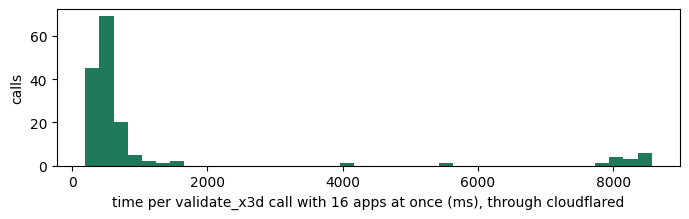

In [45]:
#@title 5d · Many at once { display-mode: "form" }
async def worker(lat, errors):
    try:
        async with session() as s:
            for _ in range(LOAD_CALLS_PER_SESSION):
                t = time.perf_counter()
                try:
                    r = await s.call_tool("validate_x3d", {"content": GOOD})
                    if r.isError or not json.loads(text_of(r)).get("valid"):
                        errors.append("wrong answer")
                except Exception as e:
                    errors.append(type(e).__name__)
                lat.append((time.perf_counter() - t) * 1000)
    except Exception as e:
        errors.append("could not connect: %s" % type(e).__name__)

async def part_d():
    lat, errors = [], []
    before = rss_mb()
    t = time.perf_counter()
    await asyncio.gather(*(worker(lat, errors) for _ in range(LOAD_SESSIONS)))
    wall = time.perf_counter() - t
    total = LOAD_SESSIONS * LOAD_CALLS_PER_SESSION
    record("5d", "%d apps × %d validations at once" % (LOAD_SESSIONS, LOAD_CALLS_PER_SESSION), "FAIL" if errors else "PASS", wall * 1000,
           "%d/%d answered correctly · %.1f calls per second%s" % (total - len(errors), total, total / wall,
                                                                     " · errors: %s" % sorted(set(errors)) if errors else ""))
    if lat:
        q = statistics.quantiles(lat, n=100) if len(lat) > 1 else [lat[0]] * 99
        record("5d", "time per call: typical / slow / slowest", "PASS", q[49],
               "%.0f ms typical (median) · %.0f ms for the slowest 5%% · %.0f ms worst" % (q[49], q[94], max(lat)))
    after = rss_mb()
    record("5d", "server memory", "PASS" if after - before < 300 else "WARN", None, "%.0f MB before → %.0f MB after" % (before, after))
    record("5d", "server still alive afterwards", "PASS" if server_alive() else "FAIL")
    return lat

LATENCIES = run(part_d())
table("5d")
print("💡 Typical (median) = half the calls were faster. The slowest 5 %% is what an unlucky user feels. With %d apps at once "
      "on %s CPU cores, calls wait in line: try LOAD_SESSIONS = 1 to see how much of the time is queueing." % (LOAD_SESSIONS, os.cpu_count()))
try:
    import matplotlib.pyplot as plt
    plt.figure(figsize=(7, 2.3))
    plt.hist(LATENCIES, bins=40, color="#1f7a5c")
    plt.xlabel("time per validate_x3d call with %d apps at once (ms), %s" % (LOAD_SESSIONS, ROUTE)); plt.ylabel("calls")
    plt.tight_layout(); plt.show()
except Exception:
    pass

## 6 · Scorecard

Everything in one table, plus a JSON file with the server, its commit, the package versions and every result (in the files folder 📁; tick `DOWNLOAD` to download it). Keep the JSON of each server and you can compare them later.

In [46]:
#@title 6 · Scorecard { display-mode: "form" }
DOWNLOAD = True  #@param {type:"boolean"}
import platform
counts = {s: sum(r["status"] == s for r in RESULTS) for s in COLORS}
report = {"server": REPO, "ref": GIT_REF, "commit": COMMIT, "tunnel": TUNNEL, "tested": ROUTE, "mcp_pinned_below_2": PIN_MCP_BELOW_2,
          "server_info": {"name": INIT.serverInfo.name, "version": INIT.serverInfo.version, "protocol": INIT.protocolVersion},
          "tools": len(TOOLS), "versions": {n: md.version(n) for n in ("mcp", "x3d", "lxml", "xmlschema")
                                           if n in {d.metadata["Name"].lower() for d in md.distributions()}},
          "python": sys.version.split()[0], "platform": platform.platform(terse=True), "cpus": os.cpu_count(),
          "load": {"sessions": LOAD_SESSIONS, "calls_per_session": LOAD_CALLS_PER_SESSION},
          "time": time.strftime("%Y-%m-%d %H:%M:%S %Z"), "summary": counts, "results": RESULTS}
REPORT_PATH = os.path.join(WORK, "x3d_mcp_starter_%s_%s.json" % (SERVER, time.strftime("%Y%m%d-%H%M%S")))
with open(REPORT_PATH, "w") as fh:
    json.dump(report, fh, indent=1)
word = ("❌ some checks FAILED" if counts["FAIL"] else "⚠️ passed, with warnings" if counts["WARN"] else "✅ everything passed")
display(HTML("<div style='font:17px system-ui;margin:6px 0'><b>%s</b> (%s) · %d tools · tested %s: %s</div>"
             % (REPO, COMMIT.split("·")[0], len(TOOLS), ROUTE, word)))
table()
print("Saved:", REPORT_PATH)
if DOWNLOAD:
    try:
        from google.colab import files
        files.download(REPORT_PATH)
    except Exception as e:
        print("download only works in Colab:", e)

test,status,check,ms,detail
5a,PASS,handshake (initialize),170,x3d-mcp 1.30.0 · MCP protocol 2025-11-25
5a,PASS,server explains itself (instructions),,3693 characters
5a,PASS,ping,235,
5a,PASS,list of tools,,48 tools
5a,PASS,every tool has a description,,
5a,PASS,resources (read-only documents),,1: x3d-ontology://turtle
5a,PASS,prompts (ready-made instructions),,"4: build_scene, audit_scene, animate_scene, convert_to_x3dom"
5a,PASS,"made-up tool refused, connection survives",,
5b,PASS,describe_node Transform,1070,"Transform: Grouping component, level 1, 19 fields, goes in a parent's 'children'"
5b,PASS,list_profiles,227,"8 profiles: Core, Interchange, CADInterchange, Interactive, Immersive, MedicalInterchange, MPEG4Interactive, Full"


Saved: /content/x3d_mcp_starter_hagopjay_20261111-100700.json


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 7 · Try it yourself

**7a 🧩 Challenge:** `MY_X3D` holds a small scene (a red box next to a green ball) with **three mistakes**. Run the cell, read the complaints, fix `MY_X3D` in the form, run again. When it is valid you see it in 3D. Stuck? The glossary at the top helps; the answer is at the end of Troubleshooting. You can also pick one of the test scenes, or paste your own X3D (one line is fine).

**7b** calls any tool by name with JSON arguments; the list of tool names is under 5a. In `ARGS`, `"$GOOD"` and `"$GOOD2"` stand for the lantern and the sphere.

In [47]:
#@title 7a · Check a scene { display-mode: "form" }
SCENE = "MY_X3D (the challenge, or your own)"  #@param ["MY_X3D (the challenge, or your own)", "good: spinning lantern", "good: sphere", "broken: Python boolean True", "broken: ROUTE type mismatch", "broken: USE before its DEF", "broken: unclosed tag"]
MY_X3D = '<X3D profile="Interchange" version="4.0"><Scene><Viewpoint position="1.5 0 8"/><Shape><Appearance><Material difuseColor="1 0 0"/></Appearance><Box size="2 2 2" solid="True"/></Shape><Transform translation="3 0 0"><Shape><Appearance><Material diffuseColor="0 1.5 0"/></Appearance><Sphere/></Shape></Transform></Scene></X3D>'  #@param {type:"string"}

if SCENE.startswith("MY_X3D"):
    xml = MY_X3D
elif SCENE.startswith("good"):
    xml = GOOD if "lantern" in SCENE else GOOD2
else:
    xml = DEFECTS[SCENE.split(": ", 1)[1]][0](GOOD)

async def check_one():
    async with session() as s:
        ok, sem, first = await verdict(s, xml)
        first = json.loads(text_of(await s.call_tool("validate_x3d", {"content": xml}))).get("errors") or [first]
        raw = text_of(await s.call_tool("validate_semantic", {"content": xml}))
        hints = None
        if not (ok and not sem) and "exact_fix_hints" in HAVE:
            hints = text_of(await s.call_tool("exact_fix_hints", {"content": xml}))
        return ok, sem, first, raw, hints

ok, sem, first, raw, hints = run(check_one())
if ok and not sem:
    print("🎉 Valid! The schema and the semantic checks are happy." + (" You fixed all three mistakes." if SCENE.startswith("MY_X3D") and "difuse" not in MY_X3D else ""))
    view3d(xml, "Your scene")
else:
    print("❌ Not valid yet: %d problem(s) found. Fixing one can reveal the next, so run again after each change." % ((0 if ok else len(first)) + len(sem)))
    for e in ([] if ok else first):
        print("   schema:  ", e)
    for e in sem:
        print("   semantic:", e)
if hints:
    print("\nHow to fix it (exact_fix_hints, hagopjay only):\n" + hints[:2500])
if VERBOSE:
    print("\nFull semantic report:\n" + raw[:4000])

❌ Not valid yet: 4 problem(s) found. Fixing one can reveal the next, so run again after each change.
   schema:   Line 1: Element 'Material', attribute 'difuseColor': The attribute 'difuseColor' is not allowed.
   schema:   Line 1: Element 'Box', attribute 'solid': 'True' is not a valid value of the atomic type 'SFBool'.
   schema:   Line 1: Element 'Material', attribute 'diffuseColor': [facet 'pattern'] The value '0 1.5 0' is not accepted by the pattern '\s*(([+]?((0(\.[0-9]*)?|\.[0-9]+)|1(\.0*)?)([Ee][+-]?[0-9]+)?)\s+){2}([+]?((0(\.[0-9]*)?|\.[0-9]+)|1(\.0*)?)([Ee][+-]?[0-9]+)?)\s*'.
   semantic: colour-out-of-range

How to fix it (exact_fix_hints, hagopjay only):
{
  "valid": false,
  "errors": [
    "Line 1: Element 'Material', attribute 'difuseColor': The attribute 'difuseColor' is not allowed.",
    "Line 1: Element 'Box', attribute 'solid': 'True' is not a valid value of the atomic type 'SFBool'.",
    "Line 1: Element 'Material', attribute 'diffuseColor': [facet 'pattern'] The 

In [48]:
#@title 7b · Call any tool { display-mode: "form" }
TOOL = "describe_node"  #@param {type:"string"}
ARGS = '{"node_type": "Material"}'  #@param {type:"string"}

async def try_tool():
    args = json.loads(ARGS.replace('"$GOOD2"', json.dumps(GOOD2)).replace('"$GOOD"', json.dumps(GOOD)))
    async with session() as s:
        t = time.perf_counter()
        r = await s.call_tool(TOOL, args)
        print("%s answered in %.0f ms%s\n" % (TOOL, (time.perf_counter() - t) * 1000, " (as an error)" if r.isError else ""))
        print(text_of(r)[:6000])
        for c in r.content:
            if getattr(c, "type", "") == "image":
                display(HTML("<img src='data:image/png;base64,%s' width=320>" % c.data))

if TOOL not in HAVE:
    print("❌ This server has no tool called %r. Close ones: %s" % (TOOL, ", ".join(n for n in names if TOOL.split("_")[0] in n)[:300] or "see the list under 5a"))
else:
    run(try_tool())

describe_node answered in 1150 ms

{
  "name": "Material",
  "component": "Shape",
  "level": 1,
  "baseType": "X3DOneSidedMaterialNode",
  "containerField": "material",
  "fields": [
    {
      "name": "ambientIntensity",
      "type": "SFFloat",
      "accessType": "inputOutput",
      "default": "0.2",
      "description": "how much ambient omnidirectional light is reflected from all light sources.",
      "minInclusive": "0",
      "maxInclusive": "1",
      "tooltip": "[0,1] how much ambient omnidirectional light is reflected from all light sources.",
      "hints": [
        "in Interchange profile this field may be ignored, applying the default value regardless."
      ]
    },
    {
      "name": "ambientTexture",
      "type": "SFNode",
      "accessType": "inputOutput",
      "default": "NULL",
      "description": "When applying ambientIntensity for this material node, the contained texture provides Physically Based Rendering (PBR) modulation for each pixel.",
      "accept

## 8 · Stop

Stops the tunnel, the gatekeeper and the server. The public address and the password stop working at once. (Closing the tab does not stop a Colab runtime right away: *Runtime › Disconnect and delete runtime* does.)

In [49]:
#@title 8 · Stop everything { display-mode: "form" }
stop_tunnels()
if "proxy_server" in globals():
    proxy_server.should_exit = True
if "xite_http" in globals():
    xite_http.shutdown()
server.terminate()
try:
    server.wait(5)
except subprocess.TimeoutExpired:
    server.kill()
print("✅ Stopped. The last lines the server wrote:")
show_log(6)

✅ Stopped. The last lines the server wrote:
INFO:     Waiting for application shutdown.
[11/11/26 10:07:17] INFO     StreamableHTTP       streamable_http_manager.py:168
                             session manager                                    
                             shutting down                                      
INFO:     Application shutdown complete.
INFO:     Finished server process [8502]



## Insights: what running this taught us

**The two servers**
* **hagopjay has 48 tools, consortium 34.** All 34 are shared; the fork adds exact fix hints (`exact_fix_hints`, `repair_x3d`), placement help (`where_can_place`), a generation schema for AIs, a blob store for big scenes, Gaussian-splat tools and a claims ledger.
* **The fork catches more.** On consortium `main` (Oct 2026) two broken lantern scenes in 5c slip through: a ROUTE before its DEF, and PBR materials outside the declared profile. A larger fuzzing run in x3d.lab's 03 notebook (thousands of generated scenes) found that consortium also misses nodes outside the declared profile and face indices that point past the coordinate list. It catches 95.2 % of broken scenes against the fork's 97.6 %.
* **Blind spots they share:** a `USE` node that also sets fields (`<Shape USE="A" bboxSize="1 1 1"/>`) is accepted by both, though X3D allows nothing but `containerField` there. And the X3D schema itself rejects colours written in exponent form even when they are in range: `diffuseColor="0.5 1.5e-1 0.2"` (0.15) fails, `0.15` passes. Any exporter that writes numbers `%e`-style is rejected by both servers.
* **Why `PIN_MCP_BELOW_2` exists:** consortium's `pyproject.toml` asks for `mcp>=1.7` with no ceiling. `mcp` 2.x removed `mcp.server.fastmcp`, which the server imports, so a plain install crashes at start-up. The fork pins `mcp<2` itself.
* **Auto-fixers are not validators.** Both servers' `autofix_x3d`, and hagopjay's `repair_x3d`, return `solid="True"` unchanged (`autofix_x3d` even reports 0 changes and 0 unfixable problems), although the schema rejects it. 5b re-validates every "fixed" answer for exactly that reason.
* hagopjay's `render_current_scene` returns a blank picture for a scene that `render_image` draws when given the same XML: a server bug. The full smoke test (x3d.lab's 00 Basic notebook) checks it automatically.

**The plumbing**
* **Two passwords, not one.** Apps send `MCP_TOKEN` to the gatekeeper; the gatekeeper swaps it for `SERVER_TOKEN` towards the server. Apps never learn the server's own token, and you can change who has access without restarting the server.
* **Host rewrite.** The MCP library refuses requests whose `Host` header is not an address it expects (protection against *DNS rebinding*, where a web page tricks your browser into talking to a local server). Behind a tunnel the Host is `….trycloudflare.com`, so the gatekeeper sets it back to `127.0.0.1:8000`: the protection stays on, the tunnel still works.
* **`accept-encoding: identity`** asks the server for uncompressed answers. MCP answers can be *streams* (server-sent events); a compressed stream can be held back until it is complete, which looks like a hang.
* **cloudflared writes to a log file, not a pipe.** An unread pipe fills up after 64 KB and cloudflared then blocks: the tunnel dies minutes later for no visible reason.
* **Stale servers.** A server started with `start_new_session=True` survives a kernel restart. An earlier notebook's health check was answered by such an old server while the new one had already crashed (exit code 3). Section 3 now stops old listeners and checks the process id.
* **Colab's own port forwarding** needs your Google login cookie, which MCP apps don't have; that is why the public options are tunnels.
* **Tunnel cost.** Compare 5d with `TEST_THROUGH_TUNNEL` on and off: each call through a tunnel makes a round trip to the tunnel provider and back. Most of the gap is network distance, not the server.
* **ngrok:** the *authtoken* starts the tunnel; an *API key* is for ngrok's REST API and is refused (`ERR_NGROK_105`). One agent at a time on the free plan (`ERR_NGROK_108`). Its "you are about to visit" warning page appears only for web browsers; apps, and this notebook (which sends `ngrok-skip-browser-warning`), never see it.

**Where to go next:** x3d.lab's **00 Basic MCP** notebook calls every tool, sends 0.5–20 MB scenes and hostile input; **01 Quickstart** adds an AI (OpenAI, Claude or Gemini) that writes scenes with these tools.

## Troubleshooting

| You see | Why | Do this |
|---|---|---|
| `NameError: name '…' is not defined` | a cell was skipped or the runtime restarted | *Runtime › Run before* on the cell, or *Run all* |
| Section 3: *exit code 1* and `mcp.server.fastmcp` in the log | `mcp` 2.x got installed | tick `PIN_MCP_BELOW_2`, *Runtime › Restart session*, *Run all* |
| Section 3: *someone else is answering on the port* | an old server is stuck | rerun section 3; if it persists, *Runtime › Disconnect and delete runtime* |
| Section 4: *cloudflared did not give us an address* / 429 | Cloudflare limits how fast quick tunnels can be created | wait a minute and rerun section 4, or use ngrok |
| `ERR_NGROK_105` | an API key (or a typo) instead of the authtoken | copy the **authtoken** from the ngrok dashboard into secret `NGROK_AUTHTOKEN` |
| `ERR_NGROK_107` | the authtoken was reset | copy the current one again |
| `ERR_NGROK_108` | ngrok is already running on another machine with your account | stop it there, or use cloudflared |
| ngrok: *needs your free authtoken* though you saved it | the secret's *Notebook access* switch is off | 🔑 panel: switch it on for `NGROK_AUTHTOKEN` |
| Claude Code: 401 or *connection failed* | new runtime = new address and password | rerun section 4, `claude mcp remove x3d-colab`, paste the new command |
| 5b: `render_image` blank | X_ITE could not load from its CDN | tick `LOCAL_XITE` (hagopjay only) |
| 5d: errors under load through the tunnel | the tunnel's free plan is throttling, or too many sessions for 2 CPU cores | fewer `LOAD_SESSIONS`, or untick `TEST_THROUGH_TUNNEL` |
| 7a challenge: stuck | | the answer: `difuseColor` → `diffuseColor`; `solid="True"` → `solid="true"`; green `0 1.5 0` → `0 1 0` (each colour channel runs from 0 to 1) |
| pip warns *you must restart the runtime* | Colab had loaded an older copy of a package | usually harmless here; if an import fails later, *Runtime › Restart session* and *Run all* |